In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torch.cuda.amp import autocast
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import lightgbm as lgb
from transformers import AutoTokenizer, AutoModel, pipeline, AutoModelForSequenceClassification, get_scheduler, TrainingArguments, Trainer, AdamW
import shap
import os
import optuna
from collections import Counter
import shap

2024-09-14 16:53:21.896192: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


# 1. Datenverarbeitung und -exploration

Insgesamt liegen als Datensatz zwei .csv-Dateien vor. Diese werden zunächst jeweils in einen pandas dataframe geladen.

In [2]:
file_path_train = '/home/rikep001/NLP/Data/medical_tc_train.csv'
train_df = pd.read_csv(file_path_train)
train_df.head(10)

,condition_label,medical_abstract
0,5,Tissue changes around loose prostheses. A cani...
1,1,Neuropeptide Y and neuron-specific enolase lev...
2,2,"Sexually transmitted diseases of the colon, re..."
3,1,Lipolytic factors associated with murine and h...
4,3,Does carotid restenosis predict an increased r...
5,3,The shoulder in multiple epiphyseal dysplasia....
6,2,The management of postoperative chylous ascite...
7,4,Pharmacomechanical thrombolysis and angioplast...
8,5,Color Doppler diagnosis of mechanical prosthet...
9,5,Noninvasive diagnosis of right-sided extracard...


In [3]:
file_path_test = '/home/rikep001/NLP/Data/medical_tc_test.csv'
test_df = pd.read_csv(file_path_test)
test_df.head(10)

,condition_label,medical_abstract
0,3,Obstructive sleep apnea following topical orop...
1,5,Neutrophil function and pyogenic infections in...
2,5,A phase II study of combined methotrexate and ...
3,1,Flow cytometric DNA analysis of parathyroid tu...
4,4,Paraneoplastic vasculitic neuropathy: a treata...
5,1,Treatment of childhood angiomatous diseases wi...
6,1,Expression of major histocompatibility complex...
7,1,Questionable role of CNS radioprophylaxis in t...
8,5,Reversibility of hepatic fibrosis in experimen...
9,2,Current status of duplex Doppler ultrasound in...


Die beiden dataframes werden nun zu einem dataframe zusammengefügt, um über mehr Daten zu verfügen. Zur Überprüfung werden die ersten zehn Zeilen des dataframes angezeigt.

In [4]:
ma_df = pd.concat([train_df, test_df], ignore_index=True)
ma_df.head(10)

,condition_label,medical_abstract
0,5,Tissue changes around loose prostheses. A cani...
1,1,Neuropeptide Y and neuron-specific enolase lev...
2,2,"Sexually transmitted diseases of the colon, re..."
3,1,Lipolytic factors associated with murine and h...
4,3,Does carotid restenosis predict an increased r...
5,3,The shoulder in multiple epiphyseal dysplasia....
6,2,The management of postoperative chylous ascite...
7,4,Pharmacomechanical thrombolysis and angioplast...
8,5,Color Doppler diagnosis of mechanical prosthet...
9,5,Noninvasive diagnosis of right-sided extracard...


In [5]:
print(ma_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14438 entries, 0 to 14437
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   condition_label   14438 non-null  int64 
 1   medical_abstract  14438 non-null  object
dtypes: int64(1), object(1)
memory usage: 225.7+ KB
None


Der Datensatz enthält pro Spalte jeweils 14438 Einträge und keine null-Einträge.

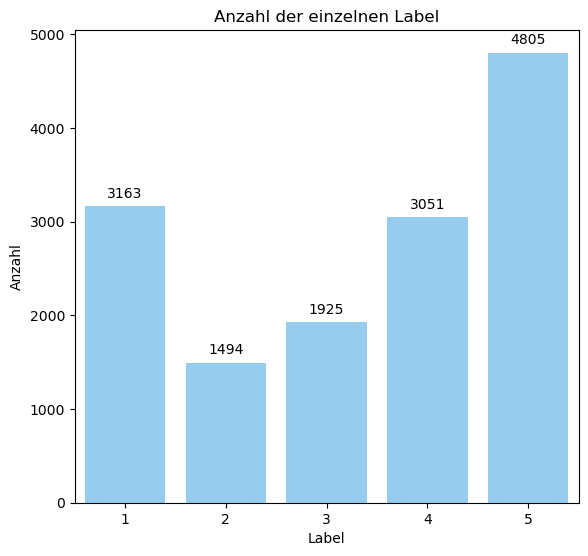

In [6]:
plt.figure(figsize=(6.5, 4.5))
countplot = sns.countplot(x='condition_label', data=ma_df, color='lightskyblue')
sns.set_palette('bright')
plt.title("Anzahl der einzelnen Label")
plt.xlabel("Label")
plt.ylabel("Anzahl")
for p in countplot.patches:
    countplot.annotate(format(p.get_height(), '.0f'), (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 9), textcoords='offset points')
plt.subplots_adjust(top=1.2, bottom=0.15)
plt.show()

Der Datensatz enthält . Auffällig ist, dass die Anzahl der einzelnen Label im Datensatz nicht gleich verteilt ist und dieser beispielsweise über deutlich mehr Diagnosen mit dem Label 5 als mit dem Label 2 verfügt. Um eine bessere Übersicht über die Form und den Inhalt der Diagnosen zu erhalten, werden drei verschiedene Diagnosen ausgewählt und angezeigt.

In [7]:
print(ma_df.iloc[1, 1])

Neuropeptide Y and neuron-specific enolase levels in benign and malignant pheochromocytomas. Neuron-specific enolase (NSE) is the isoform of enolase, a glycolytic enzyme found in the neuroendocrine system. Neuropeptide Y (NPY) is a peptide recently discovered in the peripheral and central nervous systems. Serum NSE and plasma NPY levels have been reported to be increased in some patients with pheochromocytoma. The authors evaluated whether the measurement of these molecules could help to discriminate between benign and malignant forms of pheochromocytoma. The NSE levels were normal in all patients with benign pheochromocytoma (n = 13) and elevated in one half of those with malignant pheochromocytoma (n = 13). Plasma NPY levels were on the average significantly higher in the malignant (177.1 +/- 38.9 pmol/l, n = 16) than in the benign forms of the disease (15.7 +/- 389 pmol/l, n = 24). However, there was no difference in the percentage of patients with elevated NPY levels. These results

In [8]:
print(ma_df.iloc[11111, 1])

Drug response at electropharmacologic study in patients with ventricular tachyarrhythmias: the importance of ventricular refractoriness. The clinical and electrophysiologic predictors of successful antiarrhythmic drug therapy for patients with inducible ventricular tachycardia were evaluated in 59 consecutive patients undergoing serial electropharmacologic trials. Structural heart disease was less frequently present in patients for whom effective therapy was found (p less than 0.05). The presence of coronary artery disease and a history of prior myocardial infarction were significantly more frequently present in patients for whom antiarrhythmic drug therapy could not be found (p less than 0.05). The corrected QT interval and ventricular effective refractory period measured at a pacing cycle length of 400 ms were significantly shorter in responders compared with nonresponders (QT interval 428 +/- 52 versus 460 +/- 59 ms; ventricular effective refractory period 237 +/- 28 versus 254 +/- 

In [9]:
print(ma_df.iloc[3333, 1])

The melanocyte and melanoma. This paper reviewed some of the interesting biological aspects of melanocytes and their relationship to the nevus and to melanoma. It also proposed a rationale for "adequate" surgery in the management of melanoma according to level, depth, margins, and trends in treatment. These propositions were derived from an analysis of 995 cases of melanoma of the head and neck. 


# 2. Textvorverarbeitung

Die einzelnen Diagnosen sollen nun vorverarbeitet werden, indem alle Wörter in allen Zeilen der Spalte *medical_abstract* des Datensatzes kleingeschrieben werden.

In [10]:
def normalisierung_text(text):
    return text.lower()
ma_df['medical_abstract'] = ma_df['medical_abstract'].apply(normalisierung_text)
print(ma_df.iloc[11111, 1])

drug response at electropharmacologic study in patients with ventricular tachyarrhythmias: the importance of ventricular refractoriness. the clinical and electrophysiologic predictors of successful antiarrhythmic drug therapy for patients with inducible ventricular tachycardia were evaluated in 59 consecutive patients undergoing serial electropharmacologic trials. structural heart disease was less frequently present in patients for whom effective therapy was found (p less than 0.05). the presence of coronary artery disease and a history of prior myocardial infarction were significantly more frequently present in patients for whom antiarrhythmic drug therapy could not be found (p less than 0.05). the corrected qt interval and ventricular effective refractory period measured at a pacing cycle length of 400 ms were significantly shorter in responders compared with nonresponders (qt interval 428 +/- 52 versus 460 +/- 59 ms; ventricular effective refractory period 237 +/- 28 versus 254 +/- 

Die Texte und Labels werden zur leichteren Verarbeitung jeweils in einer Liste gespeichert.

In [11]:
texts = ma_df['medical_abstract'].tolist()
labels = ma_df['condition_label'].tolist()
print(texts[:5])
print(labels[:5])

['tissue changes around loose prostheses. a canine model to investigate the effects of an antiinflammatory agent. the aseptically loosened prosthesis provided a means for investigating the in vivo and in vitro activity of the cells associated with the loosening process in seven dogs. the cells were isolated and maintained in culture for sufficient periods of time so that their biologic activity could be studied as well as the effect of different agents added to the cells in vivo or in vitro. the biologic response as determined by interleukin-1 and prostaglandin e2 activity paralleled the roentgenographic appearance of loosening and the technetium images and observations made at the time of revision surgery. the correlation between clinical, roentgenographic, histologic, and biochemical loosening indicates that the canine model is suitable for investigating the mechanisms of prosthetic failure. a canine model permits the study of possible nonsurgical therapeutic interventions with the u

Die GPU wird auf Verfügbarkeit überprüft.

In [12]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU verfügbar. Verwende:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("GPU nicht verfügbar. Verwende CPU.")

GPU verfügbar. Verwende: NVIDIA A100-SXM4-80GB


Im nächsten Schritt wird das Modell "Bio_ClinicalBERT" aus der Hugging Face Bibliothek geladen. Bio_ClinicalBERT ist eine spezialisierte Variante von BERT, die auf medizinischen Texten trainiert wurde, insbesondere auf Texten aus dem klinischen Bereich, wie wissenschaftlichen Artikeln, elektronischen Gesundheitsakten und medizinischen Berichten. Dadurch ist dieses Modell besonders gut darin, medizinische Fachbegriffe und Zusammenhänge zu verstehen und kann für medizinische NLP-Aufgaben wie Textklassifikation, Named Entity Recognition (NER) und Fragebeantwortung verwendet werden.. Dabei wird auch der zugehörige Tokenizer geladen, der für die Tokenisierung der Texte verwendet wird.

# 3. Modell-Initialisierung und Aufteilung der Daten

In [13]:
embedding_pipeline = pipeline('feature-extraction', model="emilyalsentzer/Bio_ClinicalBERT", tokenizer="emilyalsentzer/Bio_ClinicalBERT", device=device)
tokenizer = AutoTokenizer.from_pretrained("emilyalsentzer/Bio_ClinicalBERT", use_fast=True)
model = AutoModelForSequenceClassification.from_pretrained("emilyalsentzer/Bio_ClinicalBERT", num_labels=5, hidden_dropout_prob=0.3).to(device)

/opt/conda/lib/python3.10/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
/opt/conda/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at emilyalsentzer/Bio_ClinicalBERT and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TR

Der Datensatz wird in Trainings-, Validierungs- und Testdaten aufgeteilt, wobei eine Aufteilung von 70% Trainings-, 15% Validierungs- und 15% Testdaten gewählt wurde. Die Labels müssen für die weitere Verarbeitung mit PyTorch in "0-basierte" Labels umgewandelt werden.

In [14]:
texts = ma_df['medical_abstract'].tolist()
labels = ma_df['condition_label'].tolist()
train_texts, temp_texts, train_labels, temp_labels = train_test_split(texts, labels, test_size=0.3, random_state=42)
val_texts, test_texts, val_labels, test_labels = train_test_split(temp_texts, temp_labels, test_size=0.5, random_state=42)
train_labels = [label - 1 for label in train_labels]
val_labels = [label - 1 for label in val_labels]
test_labels = [label - 1 for label in test_labels]
train_labels = np.array(train_labels)
val_labels = np.array(val_labels)
test_labels = np.array(test_labels)
print(f"Trainingsdaten: {len(train_texts)}")
print(f"Validierungsdaten: {len(val_texts)}")
print(f"Testdaten: {len(test_texts)}")

Trainingsdaten: 10106
Validierungsdaten: 2166
Testdaten: 2166


# 4. Feature Engineering

Im nächsten Schritt werden die Texte aus dem Trainings-, Validierungs- und Testdatensatz tokenisiert. Der Tokenizer wandelt die Texte in ein für das Modell verständliches Format um, indem die Wörter in numerische Repräsentationen (Tokens) umgewandelt und auf eine einheitliche Länge gebracht werden. Da die Texte jedoch länger als 512 Zeichen lang sind und ein Tensor nur eine Größe von maximal 512 umfassen darf, werden diese noch in Segmente aufgeteilt.

In [15]:
def tokenize_and_split_with_overlap(text, tokenizer, max_length=512, overlap=50):
    tokens = tokenizer.tokenize(text)
    token_segments = []
    for i in range(0, len(tokens), max_length - overlap):
        token_segments.append(tokens[i:i + max_length])
    return token_segments

Die Trainings- und Validierungstexte werden in kleinere Segmente unterteilt, um sie für die spätere Tokenisierung vorzubereiten.

In [16]:
train_segments = [tokenize_and_split_with_overlap(text, tokenizer) for text in train_texts]
val_segments = [tokenize_and_split_with_overlap(text, tokenizer) for text in val_texts]

Die Segmente werden in Batches verarbeitet, wobei jeder Batch tokenisiert wird.

In [17]:
def batch_tokenize_segments(segments, tokenizer, device, batch_size=16):
    encodings = []
    segments_as_text = [" ".join(segment) for segment in segments]
    for i in range(0, len(segments_as_text), batch_size):
        batch = segments_as_text[i:i + batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding="max_length", truncation=True, max_length=512)
        encodings.append(inputs)
    combined_encodings = {key: torch.cat([e[key] for e in encodings], dim=0) for key in encodings[0].keys()}
    return combined_encodings

Nach der Batch-Tokenisierung werden die Batches zu einem einzelnen Tensor zusammengeführt, der als Eingabe für das Modell verwendet wird.

In [18]:
train_encodings = [batch_tokenize_segments(segments, tokenizer, device, batch_size=16) for segments in train_segments]
val_encodings = [batch_tokenize_segments(segments, tokenizer, device, batch_size=16) for segments in val_segments]

Es wird die Klasse MedicalDataset erstellt, die wiederum eine Struktur bietet, die es erlaubt, Encodings und Labels in einem Dataset zu speichern und für Trainingsprozesse mit dem DataLoader zu verwenden. 

In [19]:
class MedicalDataset(Dataset):
    def __init__(self, encodings, labels):
        if isinstance(encodings, list):
            self.encodings = {key: torch.cat([e[key] for e in encodings], dim=0) for key in encodings[0].keys()}
        else:
            self.encodings = encodings        
        self.labels = labels
    def __getitem__(self, idx):
        item = {key: val[idx].clone().detach() for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx]).clone().detach()
        return item
    def __len__(self):
        return len(self.labels)

Es werden nun zwei Datensätze erstellt, die für das Training und die Evaluierung mit PyTorch verwendet werden können.

In [20]:
train_dataset = MedicalDataset(train_encodings, train_labels)
val_dataset = MedicalDataset(val_encodings, val_labels)

# 5. Modelloptimierung und -training

Da die Klassen ungleicht verteilt sind, wird die Verteilung der Klassen balanciert . 

In [22]:
class_weights = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

In [23]:
class WeightedModel(nn.Module):
    def __init__(self, model, class_weights_tensor):
        super(WeightedModel, self).__init__()
        self.model = model
        self.class_weights = class_weights_tensor
        self.loss_fct = nn.CrossEntropyLoss(weight=self.class_weights) 
    def forward(self, input_ids, attention_mask=None, labels=None):
        outputs = self.model(input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        loss = None
        if labels is not None:
            loss = self.loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, logits) if loss is not None else logits

Im nächsten erfolgt die Definition der Trainingsparametern, wobei ein AdamW-Optimizer mit einer Lernrate von 3e-5 und einer Weight Decay von 0.01 für das Modelltraining definiert werden. Das Training soll über fünf Epochen laufen, mit einer Batch-Größe von acht für sowohl Trainings- als auch Evaluierungsdaten. Es werden 500 Warmup-Schritte verwendet, um das Modell schrittweise in den Trainingseinsatz zu bringen. 

In [25]:
optimizer = AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=500,
    weight_decay=0.05,
    logging_dir='./logs',
    logging_steps=10,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    report_to="tensorboard",
    learning_rate=3e-5)
weighted_model = WeightedModel(model, class_weights_tensor)
scheduler = get_scheduler(
    name="linear", 
    optimizer=optimizer, 
    num_warmup_steps=500, 
    num_training_steps=len(train_dataset) * training_args.num_train_epochs)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    optimizers=(optimizer, scheduler))

/opt/conda/lib/python3.10/site-packages/transformers/optimization.py:591: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/transformers/training_args.py:1525: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


Es erfolgt die Erstellung des Trainers und das Training.

In [26]:
trainer.train()
trainer.evaluate()

Epoch,Training Loss,Validation Loss
1,1.544900,1.522151
2,1.548000,1.519836
3,1.580300,1.520503


{'eval_loss': 1.5205028057098389,
 'eval_runtime': 14.2234,
 'eval_samples_per_second': 152.284,
 'eval_steps_per_second': 4.781,
 'epoch': 3.0}

Die Funktion extract_logits nimmt die Texte, das Modell und den Tokenizer als Eingaben. Es wird eine Liste um die berechneten Logits für alle Texte zu speichern. Logits sind die "Roh-Ausgaben" des Modells, bevor eine Aktivierungsfunktion wie Softmax angewendet wird, um sie in Wahrscheinlichkeiten umzuwandeln. Logits repräsentieren somit nicht direkt Wahrscheinlichkeiten, sondern unskalierte Werte, die das Modell für jede Klasse berechnet. Diese Werte sind ein Maß dafür, wie sicher das Modell für jede Klasse ist, bevor die Vorhersage getroffen wird. Es wird jeder Text einzeln verarbeitet und anschließend wird der Text mit Hilfe des Tokenizers in numerische Token umgewandelt, wobei diese auf eine maximale Länge von 512 Tokens begrenzt und bei Bedarf aufgefüllt werden, um eine ungleiche Länge zu verhindern.

In [27]:
def extract_logits(texts, model, tokenizer, device, batch_size=512, max_length=512):
    model.eval()
    model.to(device)
    all_logits = []
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i+batch_size]
        inputs = tokenizer(batch_texts, return_tensors="pt", padding="max_length", truncation=True, max_length=max_length).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            logits = outputs.logits.cpu().numpy()
            all_logits.append(logits)
        torch.cuda.empty_cache()
    return np.vstack(all_logits)

Die nächste Codezeile ruft die Funktion extract_logits sowohl für die Trainings- als auch für die Validierungstexte auf. Hierbei werden die Logits für beide Datensätze berechnet und die Form (also die Anzahl der Beispiele und Klassen) der resultierenden Arrays ausgegeben. Dies ist nützlich, um sicherzustellen, dass die Dimensionen der Logits korrekt sind und den Erwartungen entsprechen.

In [28]:
train_logits = extract_logits(train_texts, model, tokenizer, device)
val_logits = extract_logits(val_texts, model, tokenizer, device)
print(f"train_logits shape: {train_logits.shape}")
print(f"val_logits shape: {val_logits.shape}")

train_logits shape: (10106, 5)
val_logits shape: (2166, 5)


Der nächste Abschnitt des Codes befasst sich mit der Anwendung von SMOTE (Synthetic Minority Over-sampling Technique) auf den Trainingsdatensatz, um ein Ungleichgewicht in der Klassenverteilung zu beheben. SMOTE erstellt synthetische Beispiele für die unterrepräsentierten Klassen, wodurch das Modell robuster wird. Danach werden die Logits extrahiert und kombiniert. Ziel ist, sowohl die echten als auch die synthetischen Daten gemeinsam als Trainingsdaten zu verwenden.

In [29]:
smote = SMOTE(random_state=42)
train_text_indices_resampled, y_train_smote_cpu = smote.fit_resample(np.arange(len(train_texts)).reshape(-1, 1), train_labels)
y_train_smote_cpu = y_train_smote_cpu.astype(int)
train_texts_resampled = [train_texts[idx[0]] for idx in train_text_indices_resampled]
train_logits_resampled = extract_logits(train_texts_resampled, model, tokenizer, device)
print(f"train_logits_resampled shape: {train_logits_resampled.shape}")
print(f"y_train_smote_cpu shape: {y_train_smote_cpu.shape}")
print(Counter(train_labels))
print(Counter(y_train_smote_cpu))

train_logits_resampled shape: (16685, 5)
y_train_smote_cpu shape: (16685,)
Counter({4: 3337, 0: 2235, 3: 2095, 2: 1373, 1: 1066})
Counter({4: 3337, 1: 3337, 2: 3337, 3: 3337, 0: 3337})


In [30]:
combined_train_logits = np.vstack([train_logits, train_logits_resampled])
combined_train_labels = np.concatenate([train_labels, y_train_smote_cpu])
print(f"Shape of combined_train_logits: {combined_train_logits.shape}")
print(f"Shape of combined_train_labels: {combined_train_labels.shape}")

Shape of combined_train_logits: (26791, 5)
Shape of combined_train_labels: (26791,)


Die folgende Zelle definiert eine Funktion, welche für die Hyperparameteroptimierung verwendet wird. Innerhalb der Funktion werden die Hyperparameter für das XGBoost-Modell festgelegt. Hierbei werden verschiedene Parameterbereiche eingstellt. Anschließend wird das Modell mit den trainierten Logits und Labels trainiert und die Vorhersagen getroffen. Die Genauigkeit dieser Vorhersagen wird berechnet und als Zielgröße für die Optimierung zurückgegeben.

In [31]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    params = {
        'objective': 'multi:softmax', 
        'num_class': 5,
        'tree_method': 'hist',
        'device': 'cuda', 
        'n_estimators': trial.suggest_int('n_estimators', 100, 500), 
        'max_depth': trial.suggest_int('max_depth', 3, 10),  
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),  
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True), 
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),  
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0)}
    model = xgb.XGBClassifier(**params)
    model.fit(combined_train_logits, combined_train_labels, verbose=False)
    preds = model.predict(val_logits)
    accuracy = accuracy_score(val_labels, preds)
    return accuracy

Die optimalen Parameter für das Modell werden ausgegeben.

In [32]:
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)
print("Beste Parameter:", study.best_params)

/opt/conda/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [17:12:20] WARNING: /workspace/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  warnings.warn(smsg, UserWarning)


Beste Parameter: {'n_estimators': 177, 'max_depth': 3, 'learning_rate': 0.010421378389007798, 'gamma': 1.2433470890160446e-07, 'subsample': 0.8026406593664879, 'colsample_bytree': 0.8189636974006516}


Im folgenden wird das Modell dann mit den kombinierten Logits und Labels aus dem Trainingsdatensatz trainiert.

In [33]:
best_model = xgb.XGBClassifier(**study.best_params)
best_model.fit(combined_train_logits, combined_train_labels)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8189636974006516, device=None,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None,
              gamma=1.2433470890160446e-07, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.010421378389007798, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=177, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)

# 6. Modellbewertung

Das trainierte Modell wird auf die Testdaten angewendet und es wird ein Bericht über die Modellleistung erstellt, der verschiedene Metriken beinhaltet.

In [34]:
def batch_predict_logits_on_segments_with_overlap(text, model, tokenizer, device='cuda', batch_size=512, max_length=512, overlap=50):
    logits_list = []
    # Text in Segmente mit Überlappung aufteilen
    segments = tokenize_and_split_with_overlap(text, tokenizer, max_length=max_length, overlap=overlap)
    segment_texts = [" ".join(segment) for segment in segments]
    for i in range(0, len(segment_texts), batch_size):
        batch = segment_texts[i:i + batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding="max_length", truncation=True, max_length=max_length).to(device)
        with torch.no_grad():
            outputs = model(**inputs)
            logits = outputs.logits.cpu().numpy()
            logits_list.append(logits)
    return np.mean(np.vstack(logits_list), axis=0)

In [35]:
segment_logits = [batch_predict_logits_on_segments_with_overlap(text, model, tokenizer) for text in test_texts]
final_predictions = [np.argmax(logits) for logits in segment_logits]
print(classification_report(test_labels, final_predictions))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       475
           1       0.00      0.00      0.00       219
           2       0.00      0.00      0.00       283
           3       0.00      0.00      0.00       474
           4       0.33      1.00      0.50       715

    accuracy                           0.33      2166
   macro avg       0.07      0.20      0.10      2166
weighted avg       0.11      0.33      0.16      2166



/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Um die Performance des besten trainierten Modells auf den kombinierten Trainingsdaten zu evaluieren, wird eine Kreuzvalidierung durchgeführt. Bei dieser Kreuzvalidierung wird der Datensatz in zehn gleich große Teile aufgeteilt, wobei das Modell zehnmal trainiert wird: Jedes Mal mit neun Teilen als Trainingsdaten und dem verbleibenden Teil als Testdaten. Dadurch wird eine robustere Schätzung der Modellleistung auf neuen Daten ermöglicht. Das Ergebnis der Kreuzvalidierung sind die Genauigkeitswerte für jeden der zehn Durchläufe, wobei hier deren gesamter Durchschnitt angezeigt wird.

In [36]:
scores = cross_val_score(best_model, combined_train_logits, combined_train_labels, cv=10, scoring='accuracy', n_jobs=1)
print(f"Durchschnittliche Cross-Validation Accuracy: {np.mean(scores)}")

Durchschnittliche Cross-Validation Accuracy: 0.3024143142072393


# 7. Modellinterpretation

Abschließend dient das Tool SHAP (SHapley Additive exPlanations) zur Interpretation des Modells und gibt Einblick in die Bedeutung einzelner Features und deren Kombinationswirkungen auf das Modell. Der Plot visualisiert, wie jedes Feature die Vorhersagen des Modells beeinflusst und wie stark es mit anderen Features interagiert.

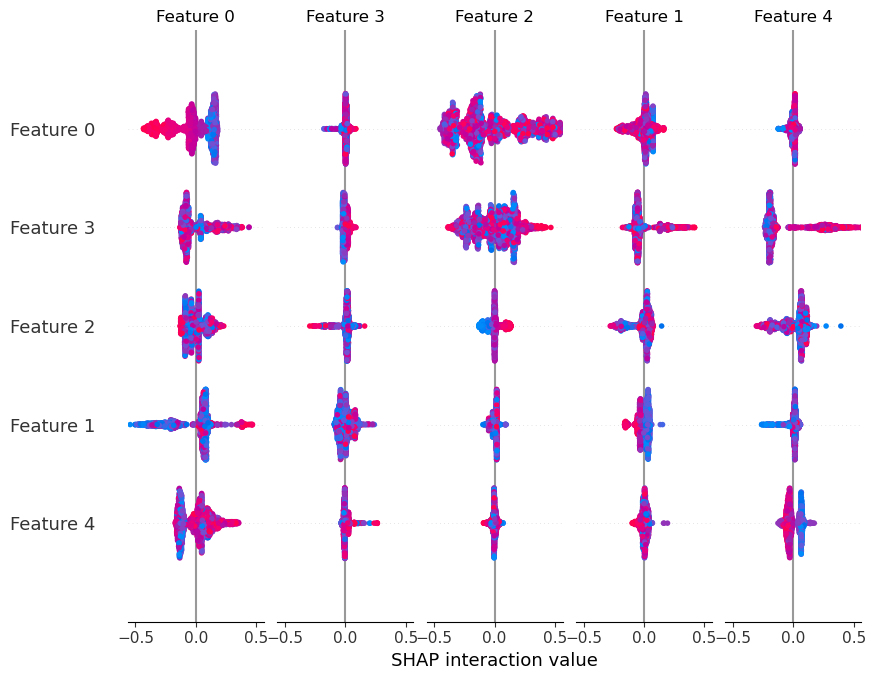

In [37]:
test_logits = extract_logits(test_texts, model, tokenizer, device)
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(test_logits)
shap.summary_plot(shap_values, test_logits)